<a href="https://colab.research.google.com/github/herbertc3/cherubyherbert/blob/main/1006_BAN482_Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Validation Set Approach

In [2]:
# Import the matplotlib library for plotting visualizations
import matplotlib.pyplot as plt
# Import the pandas library for structured data manipulation using DataFrames
import pandas as pd
# Import the train_test_split utility from scikit-learn to divide datasets into subsets
from sklearn.model_selection import train_test_split

In [3]:
# Load the bad drivers CSV dataset into a pandas DataFrame
badDrivers = pd.read_csv('bad-drivers.csv')

In [4]:
# Display the bad drivers data
badDrivers.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
0,Alabama,18.8,39,30,96,80,784.55,145.08
1,Alaska,18.1,41,25,90,94,1053.48,133.93
2,Arizona,18.6,35,28,84,96,899.47,110.35
3,Arkansas,22.4,18,26,94,95,827.34,142.39
4,California,12.0,35,28,91,89,878.41,165.63


In [5]:
# Define the proportions for splitting the dataset into training, validation, and testing sets
trainingProportion = 0.70
validationProportion = 0.10
testProportion = 0.20

# Split off the test dataset (20% of the original sample data) and keep the remaining 80%
trainingAndValidationData, testData = train_test_split(
    badDrivers, test_size=testProportion
)

# Split the remaining 80% of data into training and validation subsets according to their proportional ratio
trainingData, validationData = train_test_split(
    trainingAndValidationData,
    train_size=trainingProportion / (trainingProportion + validationProportion),
)

In [6]:
# Display training data
trainingData.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
43,Texas,19.4,40,38,91,87,1004.75,156.83
40,South Carolina,23.9,38,41,96,81,858.97,116.29
9,Florida,17.9,21,29,92,94,1160.13,144.18
47,Washington,10.6,42,33,82,86,890.03,111.62
32,New York,12.3,32,29,88,80,1234.31,150.01


In [7]:
# Display validation data
validationData.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
10,Georgia,15.6,19,25,95,93,913.15,142.80
12,Idaho,15.3,36,29,85,98,641.96,82.75
33,North Carolina,16.8,39,31,94,81,708.24,127.82
2,Arizona,18.6,35,28,84,96,899.47,110.35
27,Nebraska,14.9,13,35,93,90,732.28,114.82


In [8]:
# Display test data
testData.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
36,Oklahoma,19.9,32,29,92,94,881.51,178.86
38,Pennsylvania,18.2,50,31,96,88,905.99,153.86
14,Indiana,14.5,25,29,95,95,710.46,108.92
45,Vermont,13.6,30,30,96,95,716.20,109.61
1,Alaska,18.1,41,25,90,94,1053.48,133.93


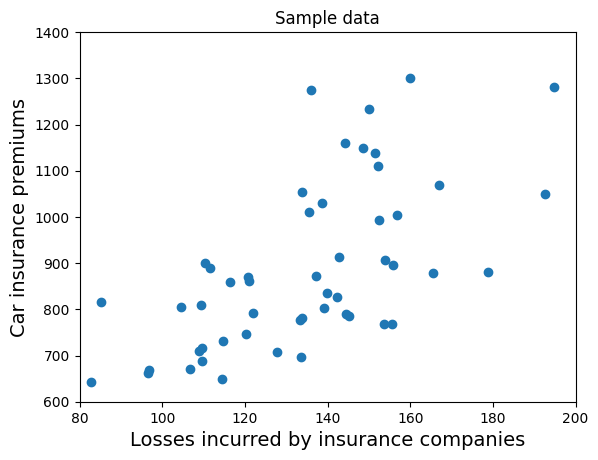

In [9]:
# Display the scatter plot for the entire sample data
plt.scatter(
    badDrivers[['Losses incurred by insurance companies for collisions per insured driver ($)']],
    badDrivers[['Car Insurance Premiums ($)']],
)
plt.xlabel('Losses incurred by insurance companies', fontsize=14)
plt.ylabel('Car insurance premiums', fontsize=14)
plt.xlim(80, 200)
plt.ylim(600, 1400)
plt.title('Sample data')
plt.show()

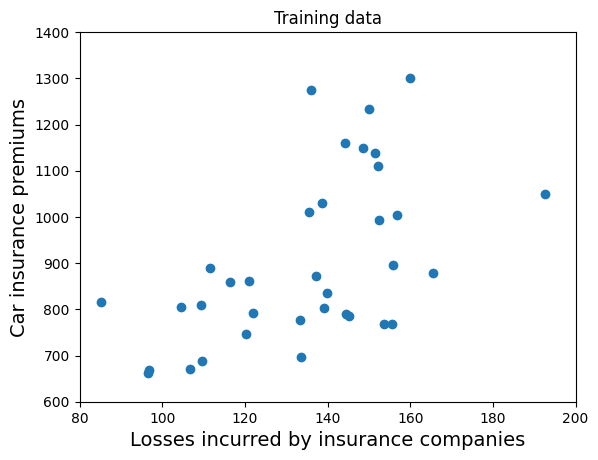

In [10]:
# Display the scatter plot for the training data
plt.scatter(
    trainingData[['Losses incurred by insurance companies for collisions per insured driver ($)']],
    trainingData[['Car Insurance Premiums ($)']],
)
plt.xlabel('Losses incurred by insurance companies', fontsize=14)
plt.ylabel('Car insurance premiums', fontsize=14)
plt.xlim(80, 200)
plt.ylim(600, 1400)
plt.title('Training data')
plt.show()

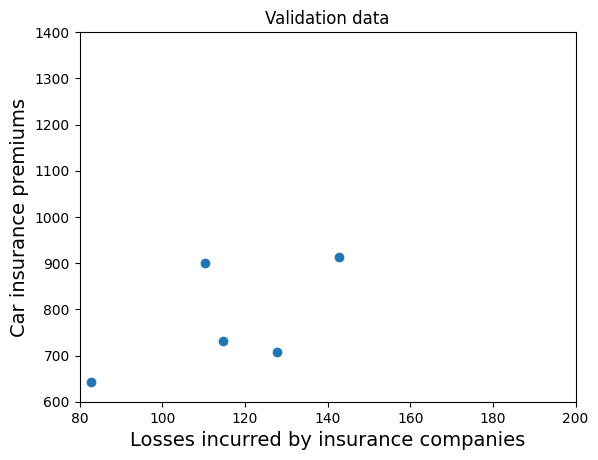

In [11]:
# Display the scatter plot for the validation data
plt.scatter(
    validationData[['Losses incurred by insurance companies for collisions per insured driver ($)']],
    validationData[['Car Insurance Premiums ($)']],
)
plt.xlabel('Losses incurred by insurance companies', fontsize=14)
plt.ylabel('Car insurance premiums', fontsize=14)
plt.xlim(80, 200)
plt.ylim(600, 1400)
plt.title('Validation data')
plt.show()

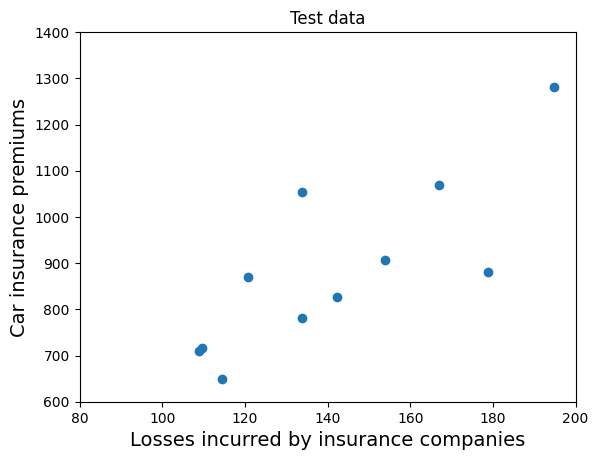

In [12]:
# Display the scatter plot for the test data
plt.scatter(
    testData[['Losses incurred by insurance companies for collisions per insured driver ($)']],
    testData[['Car Insurance Premiums ($)']],
)
plt.xlabel('Losses incurred by insurance companies', fontsize=14)
plt.ylabel('Car insurance premiums', fontsize=14)
plt.xlim(80, 200)
plt.ylim(600, 1400)
plt.title('Test data')
plt.show()

## K-Fold Cross-Validation

In [13]:
# Import matplotlib for data visualization and plotting
import matplotlib.pyplot as plt
# Import pandas for handling and exploring structured datasets
import pandas as pd
# Import numpy for high-performance mathematical operations on numerical arrays
import numpy as np
# Import linear_model module from sklearn for machine learning linear algorithms
from sklearn import linear_model
# Import the LinearRegression estimator to build standard linear regression models
from sklearn.linear_model import LinearRegression
# Import model evaluation helpers: train_test_split and cross_val_score for evaluating model performance
from sklearn.model_selection import train_test_split, cross_val_score

In [14]:
# Read the raw bad drivers CSV file into a pandas DataFrame
badDrivers = pd.read_csv('bad-drivers.csv')

# Isolate 20% of the dataset to act as an independent final test set
badDriversTrainingdata, testData = train_test_split(badDrivers, test_size=0.20)



In [15]:
# --- Setting up the Scikit Learn Workflow -----
## DEFINE
# Store the target feature (insurance premium) and predictor feature (insurance company losses)
# Reshape them into 2D arrays because scikit-learn estimators expect 2D array inputs for features
X = badDriversTrainingdata[
    ['Losses incurred by insurance companies for collisions per insured driver ($)']
    ].values.reshape(-1, 1)
y = badDriversTrainingdata[['Car Insurance Premiums ($)']].values.reshape(-1, 1)

In [16]:
badDriversTrainingdata.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
45,Vermont,13.6,30,30,96,95,716.20,109.61
46,Virginia,12.7,19,27,87,88,768.95,153.72
26,Montana,21.4,39,44,84,85,816.21,85.15
30,New Jersey,11.2,16,28,86,78,1301.52,159.85
9,Florida,17.9,21,29,92,94,1160.13,144.18


In [17]:
testData.head()

,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
29,New Hampshire,11.6,35,30,87,83,746.54,120.21
42,Tennessee,19.5,21,29,82,81,767.91,155.57
48,West Virginia,23.8,34,28,97,87,992.61,152.56
32,New York,12.3,32,29,88,80,1234.31,150.01
38,Pennsylvania,18.2,50,31,96,88,905.99,153.86


In [18]:
## INITIALIZE
# Initialize and fit the ordinary least squares linear regression model on the training features
linModel = LinearRegression()



In [19]:
## FIT, PREDICT, and EVALUATE using 10-Fold CV

# Perform 10-fold cross-validation on our regression model.
# Since scikit-learn's scorers maximize utility, they return negative MSE scores.
# We apply a minus sign (-) to convert these negative scores back to positive MSE values.
ten_fold_scores = -cross_val_score(
    linModel, X, y, scoring='neg_mean_squared_error', cv=10
)
# Output the computed MSE score for each of the 10 validation folds
ten_fold_scores

array([39757.81662671, 20044.68287815, 19846.22142093, 11625.51717886,
       45367.75843094, 10406.8124732 , 11988.48173019, 10444.47214372,
       28561.28458486, 17133.12262248])

In [20]:
## FIT, PREDICT, and EVALUATE using LOOCV

# Perform Leave-One-Out Cross-Validation (LOOCV) on our dataset.
# Since we have 40 samples in our training subset, setting cv=40 means each sample is used as a validation set once.
# We prepend the minus sign (-) to obtain positive Mean Squared Error scores.
LOOCV_scores = -cross_val_score(linModel, X, y, scoring='neg_mean_squared_error', cv=40)
# Output the computed validation MSE for each of the 40 individual data splits
LOOCV_scores

array([4.14525821e+03, 5.33091498e+04, 3.11021626e+04, 8.88619789e+04,
       4.96273071e+04, 2.65107305e+04, 6.26403768e+02, 1.49269929e+03,
       2.60038615e+04, 1.23274665e+04, 2.49543581e+04, 1.76741164e+04,
       2.86076217e+04, 2.93460061e+03, 1.23958764e+04, 1.15132756e+03,
       1.43323407e+05, 1.32617955e+04, 8.18765074e+03, 1.15032518e+04,
       2.49145416e+02, 3.28600564e+03, 2.72428575e+04, 8.77711794e+03,
       2.55848690e+04, 9.59966495e+03, 1.53200982e+04, 5.22394026e+01,
       1.58308237e+03, 2.58057928e+03, 8.99742787e+02, 3.62406953e+04,
       1.38563047e+04, 2.39421832e+04, 3.28522512e+04, 1.35921404e+04,
       4.00174162e+04, 1.29806121e+04, 1.18467938e+04, 5.35570557e+03])

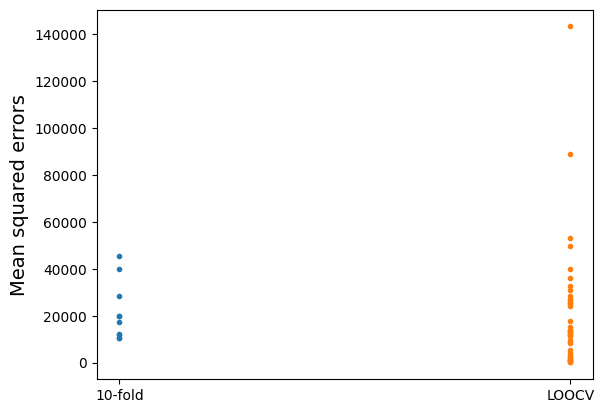

In [21]:
# Plot a comparison of the validation errors between 10-fold and LOOCV strategies
# Plot the 10-fold cross-validation scores vertically at x-coordinate 0
plt.plot(np.zeros_like(ten_fold_scores), ten_fold_scores, '.')
# Plot the LOOCV scores vertically at x-coordinate 1
plt.plot(np.zeros_like(LOOCV_scores) + 1, LOOCV_scores, '.')
# Configure the y-axis label and map the discrete x-ticks to their respective approach labels
plt.ylabel('Mean squared errors', fontsize=14);
plt.xticks([0, 1], ['10-fold', 'LOOCV']);

## Bootstrapping

In [22]:
# Import matplotlib.pyplot library for creating visualizations and plots
import matplotlib.pyplot as plt
# Import pandas library for data manipulation and analysis with DataFrames
import pandas as pd
# Import numpy library for numerical operations and array handling
import numpy as np
# Import resample function from sklearn.utils for bootstrap sampling with replacement
from sklearn.utils import resample
# Import LinearRegression class from sklearn for fitting linear regression models
from sklearn.linear_model import LinearRegression
# Import mean_squared_error function from sklearn for calculating model prediction errors
from sklearn.metrics import mean_squared_error

In [23]:
# Load data set
badDrivers = pd.read_csv('bad-drivers.csv')

In [24]:
badDrivers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 8 columns):
 #   Column                                                                                                  Non-Null Count  Dtype  
---  ------                                                                                                  --------------  -----  
 0   State                                                                                                   51 non-null     object 
 1   Number of drivers involved in fatal collisions per billion miles                                        51 non-null     float64
 2   Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding                                    51 non-null     int64  
 3   Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired                            51 non-null     int64  
 4   Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted                     

In [25]:
# Create bootstrap samples and collect errors

# Initializes an empty list to store the mean squared errors
# calculated in each bootstrap iteration.
bootstrapErrors = []

for i in range(0, 30):
    # Creates a bootstrap sample (boot) by randomly sampling 51 rows from the
    # badDrivers DataFrame with replacement. This means some rows may be
    # selected multiple times, and others may not be selected at all.
    boot = resample(badDrivers, replace=True, n_samples=51)

    # Creates the out-of-bag sample (oob) which consists of the rows from the
    # original badDrivers DataFrame that were not included in the current
    # bootstrap sample.
    oob = badDrivers[~badDrivers.index.isin(boot.index)]

    # Fit a linear model to the bootstrap sample:
    # These lines prepare the data from the bootstrap sample (boot) for the
    # linear regression model. The Losses incurred... column is used as the
    # independent variable (XBoot), and Car Insurance Premiums ($) is used as
    # the dependent variable (yBoot). A LinearRegression model is initialized
    # and then fitted (trained) using this bootstrap sample data.
    XBoot = boot[
        ['Losses incurred by insurance companies for collisions per insured driver ($)']
    ].values.reshape(-1, 1)
    yBoot = boot[['Car Insurance Premiums ($)']].values.reshape(-1, 1)
    linModel = LinearRegression()
    linModel.fit(XBoot, yBoot)

    # Predict y values for the out-of-bag sample
    # These lines prepare the data from the out-of-bag sample (oob) and use the
    # trained linear regression model (linModel) to predict the Car Insurance
    # Premiums ($) (YOobPredicted) based on the Losses incurred... values (XOob)
    # from the out-of-bag sample.
    XOob = oob[
        ['Losses incurred by insurance companies for collisions per insured driver ($)']
    ].values.reshape(-1, 1)
    YOob = oob[['Car Insurance Premiums ($)']].values.reshape(-1, 1)
    YOobPredicted = linModel.predict(XOob)

    # Calculate the error
    bootError = mean_squared_error(YOob, YOobPredicted)
    bootstrapErrors.append(bootError)

In [26]:
# Calculate the mean of the errors
np.mean(bootstrapErrors)

np.float64(21417.17454687384)

In [27]:
# Calculate the standard deviation of the errors
np.std(bootstrapErrors)

np.float64(5888.532656085873)

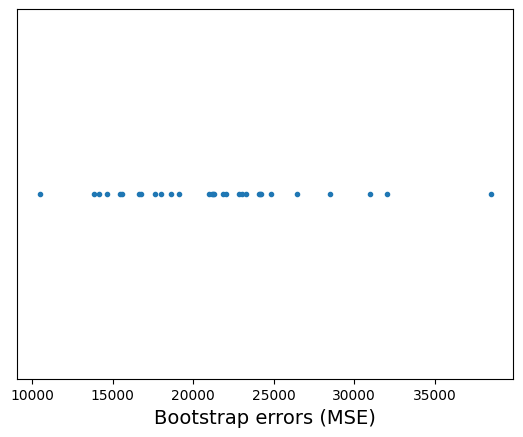

In [28]:
# Plot the errors
plt.plot(bootstrapErrors, np.zeros_like(bootstrapErrors), '.')
# This is the core plotting command.
# bootstrapErrors: This is the list containing the mean squared errors calculated
# during each bootstrap iteration. These values will be plotted on the x-axis.
# np.zeros_like(bootstrapErrors): This creates an array of zeros with the same
# shape as bootstrapErrors. This effectively sets all the y-coordinates to zero,
# causing the data points to be plotted along the x-axis.
# .: This specifies that the data points should be plotted as dots.

plt.xlabel('Bootstrap errors (MSE)', fontsize=14)
# This sets the label for the x-axis to 'Bootstrap errors (MSE)' and increases
# the font size to 14 for better readability.
plt.gca().axes.yaxis.set_ticks([]);
# This line removes the tick marks from the y-axis. Since all the data points
# are plotted on the x-axis (y=0), the y-axis doesn't convey any meaningful
# information, so removing the ticks cleans up the plot.